In [ ]:
import json
import time
from pathlib import Path
import requests

# 1. Dizin Yapılandırması (Directory Configuration)
# Doğru klasöre gitmesi için
current_dir = Path.cwd()
if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Kesin hedef: proje-koku/data/raw
raw_dir = project_root / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

print(f"Verilerin kaydedileceği hedef dizin: {raw_dir.resolve()}")

# Dizi Listesi ve API Parametreleri
# 12 ikonik yapımın TVMaze ID eşlemeleri
SHOWS = {
    "The Simpsons": 83,
    "Doctor Who": 210,
    "Friends": 431,
    "Breaking Bad": 169,
    "Game of Thrones": 82,
    "The Office": 526,
    "Brooklyn Nine-Nine": 49,
    "Grey's Anatomy": 67,
    "Supernatural": 71,
    "Stranger Things": 2993,
    "Black Mirror": 305,
    "Sherlock": 335,
}

raw_data = []
print("TVMaze API üzerinden veri toplama süreci başlatıldı...\n")

# Veri Çekme Döngüsü (Data Ingestion)
for name, show_id in SHOWS.items():
    # episodes endpoint'i diziye ait tüm bölüm detaylarını tek seferde döner
    url = f"https://api.tvmaze.com/shows/{show_id}?embed=episodes"
    
    try:
        # Zaman aşımı ve ağ hatası kontrolleri
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        
        show_json = response.json()
        raw_data.append(show_json)
        
        episodes_count = len(show_json.get("_embedded", {}).get("episodes", []))
        print(f"✓ {name:<18} -> {episodes_count} bölüm başarıyla çekildi.")
        
    except requests.exceptions.HTTPError as http_err:
        print(f"✗ HTTP Hatası ({name}): {http_err}")
    except requests.exceptions.RequestException as err:
        print(f"✗ Bağlantı Hatası ({name}): {err}")
        
    # API rate-limit sınırı
    time.sleep(0.3)

# Ham JSON Dosyasının Kaydedilmesi
output_file = raw_dir / "tvmaze_raw.json"
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(raw_data, f, ensure_ascii=False, indent=2)

print("\n" + "=" * 60)
print(f"İşlem tamamlandı! Toplam çekilen dizi: {len(raw_data)}")
print(f"Ham JSON dosyası başarıyla kaydedildi:\n-> {output_file.resolve()}")
print("=" * 60)

Verilerin kaydedileceği hedef dizin: C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Marvel Dataseti\data\raw
TVMaze API üzerinden veri toplama süreci başlatıldı...

✓ The Simpsons       -> 808 bölüm başarıyla çekildi.
✓ Doctor Who         -> 153 bölüm başarıyla çekildi.
✓ Friends            -> 236 bölüm başarıyla çekildi.
✓ Breaking Bad       -> 62 bölüm başarıyla çekildi.
✓ Game of Thrones    -> 73 bölüm başarıyla çekildi.
✓ The Office         -> 202 bölüm başarıyla çekildi.
✓ Brooklyn Nine-Nine -> 153 bölüm başarıyla çekildi.
✓ Grey's Anatomy     -> 471 bölüm başarıyla çekildi.
✓ Supernatural       -> 519 bölüm başarıyla çekildi.
✓ Stranger Things    -> 42 bölüm başarıyla çekildi.
✓ Black Mirror       -> 32 bölüm başarıyla çekildi.
✓ Sherlock           -> 12 bölüm başarıyla çekildi.

İşlem tamamlandı! Toplam çekilen dizi: 12
Ham JSON dosyası başarıyla kaydedildi:
-> C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Marvel Dataseti\data\raw\tvmaze_raw.json


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd


# 1. Proje Kök Dizinini (Root) Belirleme
# Notebook notebooks/ içindeyse bir üst dizine (proje köküne) çıkar
current_dir = Path.cwd()
if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

raw_file = project_root / "data" / "raw" / "tvmaze_raw.json"
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# 2. Ham Veriyi data/raw Altından Yükleme
with open(raw_file, "r", encoding="utf-8") as f:
    records = json.load(f)

# 3. pd.json_normalize ile Üst Bilgileri Düzleştirme (Flattening)
shows_df = pd.json_normalize(records)

cols_to_keep = [
    "id", "name", "type", "language", "genres", 
    "runtime", "averageRuntime", "rating.average", 
    "network.name", "schedule.days", "_embedded.episodes"
]
shows_df = shows_df[[c for c in cols_to_keep if c in shows_df.columns]]

# 4. explode ile Bölümleri Satırlara Açma ve Birleştirme
# Bölüm listesini satırlara patlatma
df_exploded = shows_df.explode("_embedded.episodes").reset_index(drop=True)

# İç içe bölüm objesini normalize etme
episodes_df = pd.json_normalize(df_exploded["_embedded.episodes"])
episodes_df = episodes_df.add_prefix("episode_")

# Dizi ve bölüm tablolarını yatayda birleştirme
final_df = pd.concat([df_exploded.drop(columns=["_embedded.episodes"]), episodes_df], axis=1)

# Sütun isimlerini sadeleştirme
rename_dict = {
    "name": "show_name",
    "rating.average": "show_avg_rating",
    "network.name": "network",
    "episode_id": "episode_id",
    "episode_name": "episode_name",
    "episode_season": "season",
    "episode_number": "episode_num",
    "episode_runtime": "episode_runtime",
    "episode_rating.average": "episode_rating",
    "episode_airdate": "airdate"
}
final_df = final_df.rename(columns=rename_dict)


# 5. Veri Temizleme Adımları
# a. Tekrar eden kayıtların kaldırılması
final_df = final_df.drop_duplicates(subset=["episode_id"])

# b. Veri tipleri dönüşümü
final_df["season"] = pd.to_numeric(final_df["season"], errors="coerce")
final_df["episode_num"] = pd.to_numeric(final_df["episode_num"], errors="coerce")
final_df["episode_rating"] = pd.to_numeric(final_df["episode_rating"], errors="coerce")
final_df["episode_runtime"] = pd.to_numeric(final_df["episode_runtime"], errors="coerce")
final_df["airdate"] = pd.to_datetime(final_df["airdate"], errors="coerce")

# c. Yayın günü ve birincil tür çıkarma
final_df["air_day"] = final_df["schedule.days"].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unknown"
)
final_df["primary_genre"] = final_df["genres"].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else "Unspecified"
)

# d. Eksik puan kontrolü: Puanı olmayan bölümleri filtreleme
clean_df = final_df.dropna(subset=["episode_rating"]).copy()

# 6. Temizlenmiş Veriyi data/processed Klasörüne CSV Olarak Yazma
clean_csv_path = processed_dir / "tvmaze_episodes_clean.csv"
clean_df.to_csv(clean_csv_path, index=False)

print("✓ İşlem başarıyla tamamlandı!")
print(f"✓ Temizlenmiş veri kaydedildi: {clean_csv_path.resolve()}")
print(f"✓ Analize hazır toplam bölüm sayısı: {len(clean_df)}")

✓ İşlem başarıyla tamamlandı!
✓ Temizlenmiş veri kaydedildi: C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\data\processed\tvmaze_episodes_clean.csv
✓ Analize hazır toplam bölüm sayısı: 2302


UYARI - Veri setinde bulunamayan diziler: ['Supernatural']


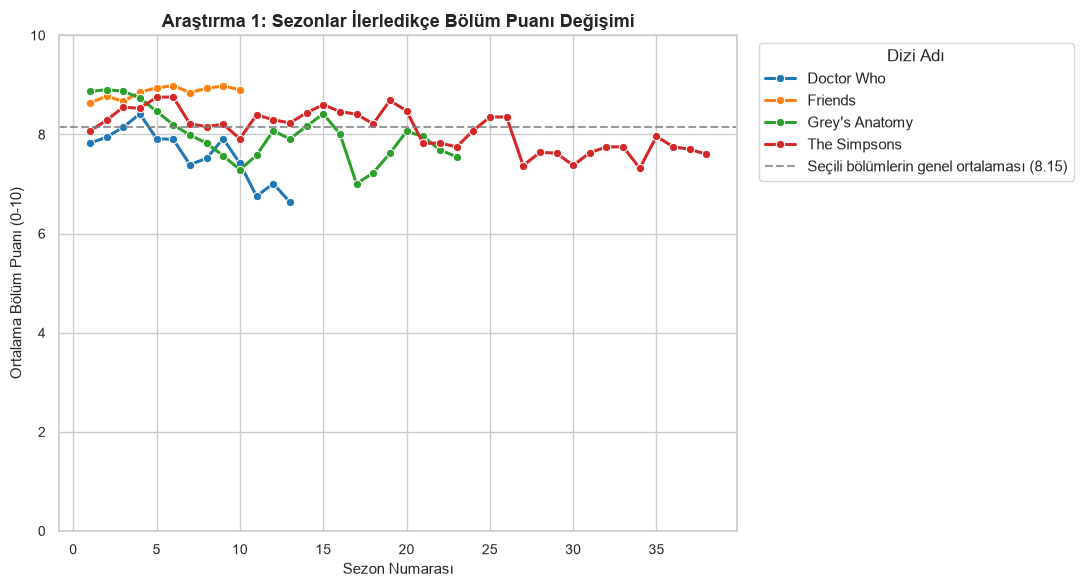


--- Araştırma 1: Sezon Eğilimleri ---
          Dizi  Sezon Sayısı Puan Eğimi (puan/sezon) Spearman Korelasyonu
    Doctor Who            13                  -0.114               -0.769
       Friends            10                   0.031                0.673
Grey's Anatomy            23                  -0.051               -0.621
  The Simpsons            38                  -0.026               -0.694

Sezon bazında puanlanan bölüm sayıları:
     show_name  season  rated_episode_count
    Doctor Who       1                   13
    Doctor Who       2                   13
    Doctor Who       3                   13
    Doctor Who       4                   13
    Doctor Who       5                   13
    Doctor Who       6                   13
    Doctor Who       7                   13
    Doctor Who       8                   12
    Doctor Who       9                   12
    Doctor Who      10                   12
    Doctor Who      11                   10
    Doctor Who      12

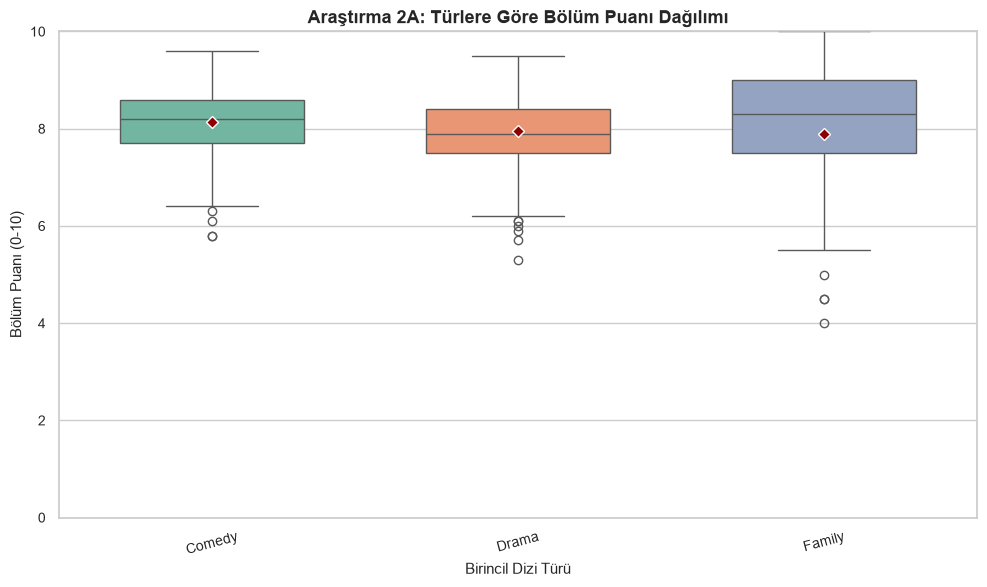

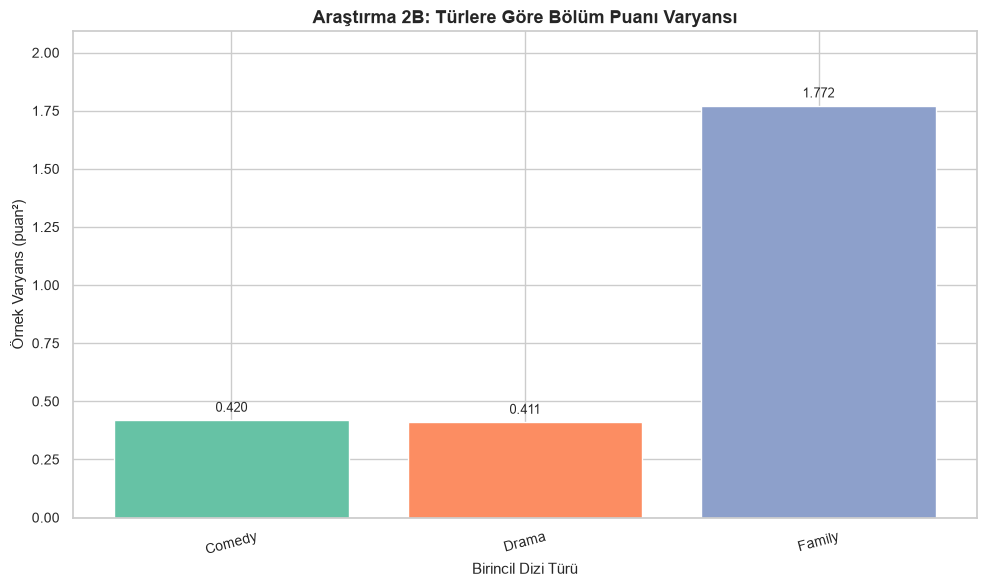


--- Araştırma 3: Süre ve Puan İlişkisi ---
Eşleşmiş gözlem sayısı (n): 2302
Pearson korelasyonu (r): -0.1094
Spearman korelasyonu (rho): -0.1202


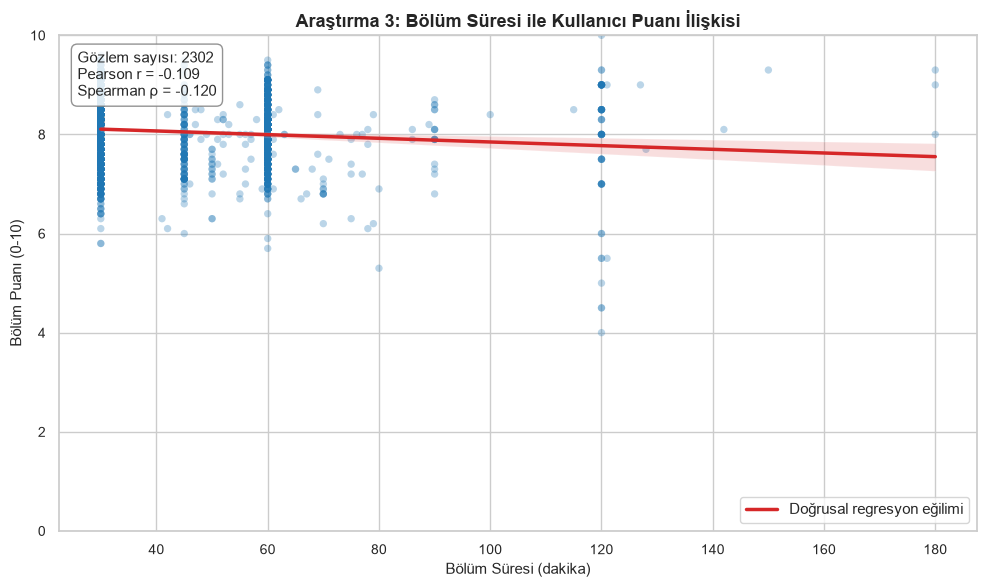


--- Üretilen Grafik Dosyaları ---
✓ c:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q1_seasonal_fatigue_lineplot.png
✓ c:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q2_genre_rating_boxplot.png
✓ c:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q2_genre_rating_variance.png
✓ c:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q3_runtime_vs_rating_scatterplot.png

Toplam üretilen grafik sayısı: 4


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import MaxNLocator

# 1. DİZİN YAPILANDIRMASI VE VERİYİ YÜKLEME
current_dir = Path.cwd()
project_root = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

clean_csv_path = (
    project_root / "data" / "processed" / "tvmaze_episodes_clean.csv"
)
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

if not clean_csv_path.exists():
    raise FileNotFoundError(
        f"Temiz veri dosyası bulunamadı: {clean_csv_path}"
    )

df = pd.read_csv(clean_csv_path)

# Gerekli sütunların mevcut olup olmadığının kontrolü
required_columns = [
    "show_name",
    "season",
    "primary_genre",
    "episode_rating",
    "episode_runtime",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Veri setinde eksik sütunlar var: {missing_columns}"
    )

# 2. VERİ TİPLERİNİ DÜZENLEME VE TEMEL KONTROLLER
# Metin sütunları
df["show_name"] = df["show_name"].astype("string").str.strip()
df["primary_genre"] = (
    df["primary_genre"].astype("string").str.strip()
)

# Sayısal sütunlar
numeric_columns = [
    "season",
    "episode_rating",
    "episode_runtime",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Puanın geçerli aralıkta olması
# TVMaze puanları 0-10 aralığında
df.loc[
    ~df["episode_rating"].between(0, 10),
    "episode_rating"
] = np.nan

# Sıfır veya negatif süreler geçerli bölüm süresi sayılmıyor.
df.loc[
    df["episode_runtime"] <= 0,
    "episode_runtime"
] = np.nan

# Grafik görsel standartları
sns.set_theme(style="whitegrid", palette="tab10")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 100,
})

saved_files = []


# ARAŞTIRMA SORUSU 1
# Sezon ilerledikçe bölüm puanları düşüyor mu?
# Grafik: Çizgi grafiği
# Sezon başına doğrusal eğim ve Spearman korelasyonu
multi_season_shows = [
    "The Simpsons",
    "Doctor Who",
    "Friends",
    "Grey's Anatomy",
    "Supernatural",
]

available_shows = set(df["show_name"].dropna().unique())

missing_shows = [
    show for show in multi_season_shows
    if show not in available_shows
]

if missing_shows:
    print(
        "UYARI - Veri setinde bulunamayan diziler:",
        missing_shows
    )

# Sezon ve puan bilgisi bulunan seçili bölümler
ms_df = df[
    df["show_name"].isin(multi_season_shows)
].dropna(
    subset=["show_name", "season", "episode_rating"]
).copy()

# Sezon 0 genellikle özel bölümleri temsil edebildiği için
# normal sezonlar arasındaki karşılaştırmaya dahil edilmiyor.
ms_df = ms_df[ms_df["season"] > 0]

# En az iki farklı sezonu bulunan dizileri seç.
season_counts = ms_df.groupby("show_name")["season"].nunique()

eligible_shows = [
    show for show in multi_season_shows
    if season_counts.get(show, 0) >= 2
]

ms_df = ms_df[
    ms_df["show_name"].isin(eligible_shows)
].copy()

if ms_df.empty:
    raise ValueError(
        "Araştırma 1 için yeterli veri bulunamadı. "
        "Dizi isimlerini ve sezon bilgilerini kontrol et."
    )

# Sezon bazında ortalama puan ve puanlanmış bölüm sayısı
season_avg = (
    ms_df.groupby(["show_name", "season"])
    .agg(
        episode_rating=("episode_rating", "mean"),
        rated_episode_count=("episode_rating", "count"),
    )
    .reset_index()
    .sort_values(["show_name", "season"])
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=season_avg,
    x="season",
    y="episode_rating",
    hue="show_name",
    marker="o",
    markersize=6,
    linewidth=2.2,
    ax=ax,
)

# Genel ortalama: seçili dizilerdeki puanlanmış tüm bölümler.
# Böylece her sezonu eşit ağırlıklandırmak yerine her bölüm
# ortalamaya kendi gözlemi olarak katkıda bulunur.
overall_mean = ms_df["episode_rating"].mean()

ax.axhline(
    overall_mean,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label=f"Seçili bölümlerin genel ortalaması ({overall_mean:.2f})",
)

ax.set_title(
    "Araştırma 1: Sezonlar İlerledikçe Bölüm Puanı Değişimi"
)
ax.set_xlabel("Sezon Numarası")
ax.set_ylabel("Ortalama Bölüm Puanı (0-10)")
ax.set_ylim(0, 10)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.legend(
    title="Dizi Adı",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
)

fig.tight_layout()

fig1_path = figures_dir / "q1_seasonal_fatigue_lineplot.png"
fig.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

saved_files.append(fig1_path)

# Her dizide sezon başına ortalama puan değişimini ölç.
# Negatif eğim düşüş, pozitif eğim yükseliş eğilimini gösterir.
trend_results = []

for show, group in season_avg.groupby("show_name"):
    group = group.sort_values("season")

    if len(group) >= 2:
        slope = np.polyfit(
            group["season"].astype(float),
            group["episode_rating"].astype(float),
            1,
        )[0]

        spearman_rho = group["season"].corr(
            group["episode_rating"],
            method="spearman",
        )

        trend_results.append({
            "Dizi": show,
            "Sezon Sayısı": len(group),
            "Puan Eğimi (puan/sezon)": slope,
            "Spearman Korelasyonu": spearman_rho,
        })

trend_table = pd.DataFrame(trend_results)

print("\n--- Araştırma 1: Sezon Eğilimleri ---")

if not trend_table.empty:
    print(
        trend_table.to_string(
            index=False,
            formatters={
                "Puan Eğimi (puan/sezon)": "{:.3f}".format,
                "Spearman Korelasyonu": "{:.3f}".format,
            },
        )
    )

print("\nSezon bazında puanlanan bölüm sayıları:")
print(
    season_avg[
        ["show_name", "season", "rated_episode_count"]
    ].to_string(index=False)
)

# ARAŞTIRMA SORUSU 2
# Türlere göre medyan ve varyans nasıl farklılaşıyor?
# Grafik 1: Kutu grafiği
# Grafik 2: Varyans sütun grafiği

genre_source = df.dropna(
    subset=["primary_genre", "episode_rating"]
).copy()

# En fazla puanlanmış bölüme sahip dört tür
top_genres = (
    genre_source["primary_genre"]
    .value_counts()
    .head(4)
    .index
    .tolist()
)

if not top_genres:
    raise ValueError(
        "Araştırma 2 için geçerli tür ve puan verisi bulunamadı."
    )

genre_df = genre_source[
    genre_source["primary_genre"].isin(top_genres)
].copy()

# Grafiklerin ve istatistiklerin aynı sırayı kullanmasını sağla.
genre_order = top_genres

# Her tür için temel istatistikler
genre_stats = (
    genre_df.groupby("primary_genre")
    .agg(
        episode_count=("episode_rating", "count"),
        median=("episode_rating", "median"),
        mean=("episode_rating", "mean"),
        variance=("episode_rating", "var"),
        std_dev=("episode_rating", "std"),
    )
    .reindex(genre_order)
)

print("\n--- Araştırma 2: Türlere Göre İstatistikler ---")
print(
    genre_stats.to_string(
        formatters={
            "median": "{:.3f}".format,
            "mean": "{:.3f}".format,
            "variance": "{:.3f}".format,
            "std_dev": "{:.3f}".format,
        }
    )
)


# Grafik 2A: Türlere göre puan dağılımı
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=genre_df,
    x="primary_genre",
    y="episode_rating",
    order=genre_order,
    hue="primary_genre",
    hue_order=genre_order,
    legend=False,
    palette="Set2",
    width=0.60,
    showfliers=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "darkred",
        "markeredgecolor": "white",
        "markersize": 6,
    },
    ax=ax,
)

ax.set_title(
    "Araştırma 2A: Türlere Göre Bölüm Puanı Dağılımı"
)
ax.set_xlabel("Birincil Dizi Türü")
ax.set_ylabel("Bölüm Puanı (0-10)")
ax.set_ylim(0, 10)
ax.tick_params(axis="x", rotation=15)

# Kutu içindeki çizgi medyanı, kırmızı elmas ortalamayı gösterir.
fig.tight_layout()

fig2_path = figures_dir / "q2_genre_rating_boxplot.png"
fig.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

saved_files.append(fig2_path)


# Grafik 2B: Türlere göre puan varyansı
fig, ax = plt.subplots(figsize=(10, 6))

variance_values = genre_stats["variance"]
colors = sns.color_palette("Set2", n_colors=len(genre_order))

bars = ax.bar(
    genre_order,
    variance_values,
    color=colors,
    edgecolor="white",
)

# Varyans değerlerini sütunların üzerinde göster.
for bar, value in zip(bars, variance_values):
    if pd.notna(value):
        ax.annotate(
            f"{value:.3f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value,
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

max_variance = variance_values.max()

ax.set_ylim(
    0,
    max_variance * 1.18
    if pd.notna(max_variance) and max_variance > 0
    else 1,
)

ax.set_title(
    "Araştırma 2B: Türlere Göre Bölüm Puanı Varyansı"
)
ax.set_xlabel("Birincil Dizi Türü")
ax.set_ylabel("Örnek Varyans (puan²)")
ax.tick_params(axis="x", rotation=15)

fig.tight_layout()

fig2b_path = figures_dir / "q2_genre_rating_variance.png"
fig.savefig(fig2b_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

saved_files.append(fig2b_path)

# ARAŞTIRMA SORUSU 3
# Bölüm süresi ile puan arasında ilişki var mı?
# Grafik: Saçılım grafiği ve doğrusal regresyon
# Pearson ve Spearman korelasyonları

runtime_rating_df = df.dropna(
    subset=["episode_runtime", "episode_rating"]
).copy()

if len(runtime_rating_df) < 2:
    raise ValueError(
        "Araştırma 3 için korelasyon hesaplamaya yeterli veri yok."
    )

# Pearson doğrusal ilişkiyi, Spearman ise sıralı/monoton ilişkiyi ölçer.
pearson_r = runtime_rating_df["episode_runtime"].corr(
    runtime_rating_df["episode_rating"],
    method="pearson",
)

spearman_rho = runtime_rating_df["episode_runtime"].corr(
    runtime_rating_df["episode_rating"],
    method="spearman",
)

sample_size = len(runtime_rating_df)

print("\n--- Araştırma 3: Süre ve Puan İlişkisi ---")
print(f"Eşleşmiş gözlem sayısı (n): {sample_size}")
print(f"Pearson korelasyonu (r): {pearson_r:.4f}")
print(f"Spearman korelasyonu (rho): {spearman_rho:.4f}")

fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=runtime_rating_df,
    x="episode_runtime",
    y="episode_rating",
    scatter_kws={
        "alpha": 0.30,
        "color": "#1f77b4",
        "s": 28,
        "edgecolor": "none",
    },
    line_kws={
        "color": "#d62728",
        "linewidth": 2.5,
        "label": "Doğrusal regresyon eğilimi",
    },
    ax=ax,
)

ax.set_title(
    "Araştırma 3: Bölüm Süresi ile Kullanıcı Puanı İlişkisi"
)
ax.set_xlabel("Bölüm Süresi (dakika)")
ax.set_ylabel("Bölüm Puanı (0-10)")

# Sabit x sınırları kullanmıyoruz. Böylece veri aralığının dışındaki geçerli gözlemler kırpılmaz.
ax.set_ylim(0, 10)

stats_text = (
    f"Gözlem sayısı: {sample_size}\n"
    f"Pearson r = {pearson_r:.3f}\n"
    f"Spearman ρ = {spearman_rho:.3f}"
)

ax.text(
    0.02,
    0.97,
    stats_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "alpha": 0.85,
        "edgecolor": "gray",
    },
)

ax.legend(loc="lower right", frameon=True)

fig.tight_layout()

fig3_path = figures_dir / "q3_runtime_vs_rating_scatterplot.png"
fig.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

saved_files.append(fig3_path)

# 4. ÇIKTILAR

print("\n--- Üretilen Grafik Dosyaları ---")

for file_path in saved_files:
    print(f"✓ {file_path}")

print(f"\nToplam üretilen grafik sayısı: {len(saved_files)}")